# Task 1 - Iris Classification

Datheon ML & Data Science Internship

In this task I train two classifiers (Logistic Regression and Decision Tree) on the Iris dataset and compare how well they do using accuracy, precision, recall and F1-score.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

## Loading the data

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
# if no internet use the local copy instead:
# df = pd.read_csv("../data/iris.csv")

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(df.shape)
print(df.isnull().sum())
df['species'].value_counts()

(150, 5)
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

150 rows, 4 features and 3 species with 50 each, so the classes are balanced. No missing values so no cleaning needed.

In [4]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## EDA

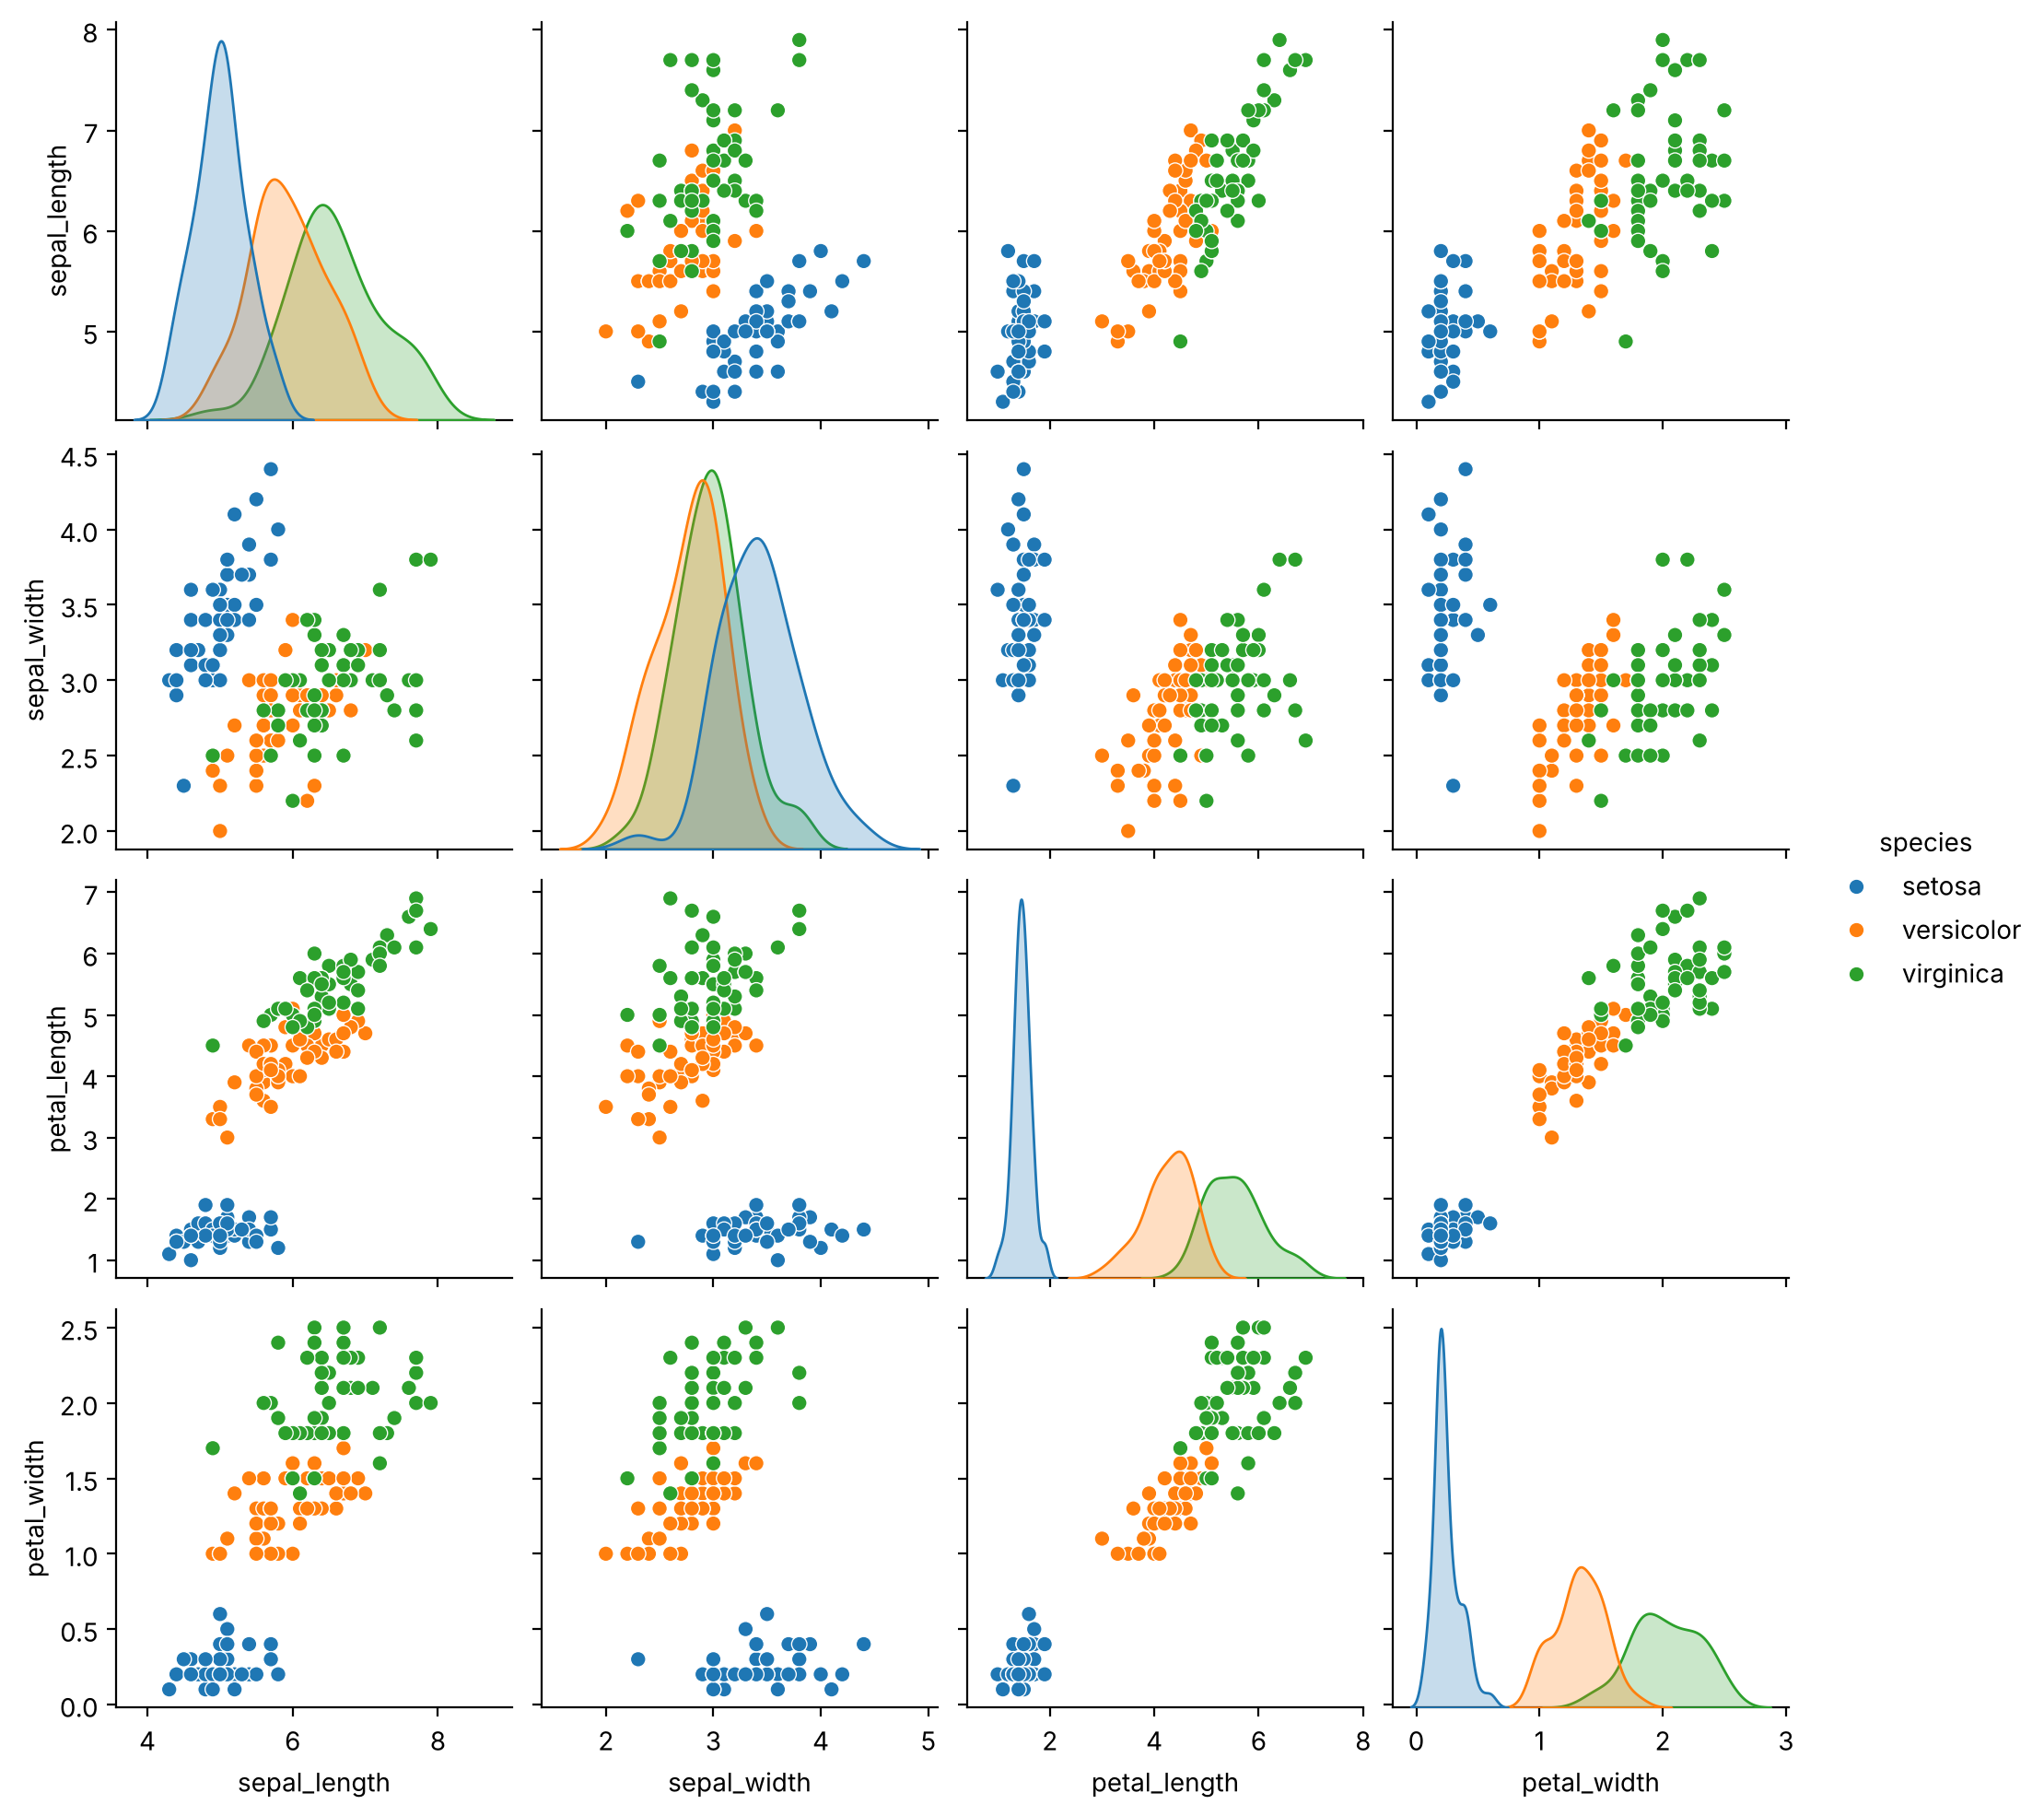

In [5]:
sns.pairplot(df, hue='species')
plt.show()

From the pairplot, setosa is completely separate from the other two, especially on petal length and petal width. Versicolor and virginica overlap a bit so I expect most of the mistakes to be between those two.

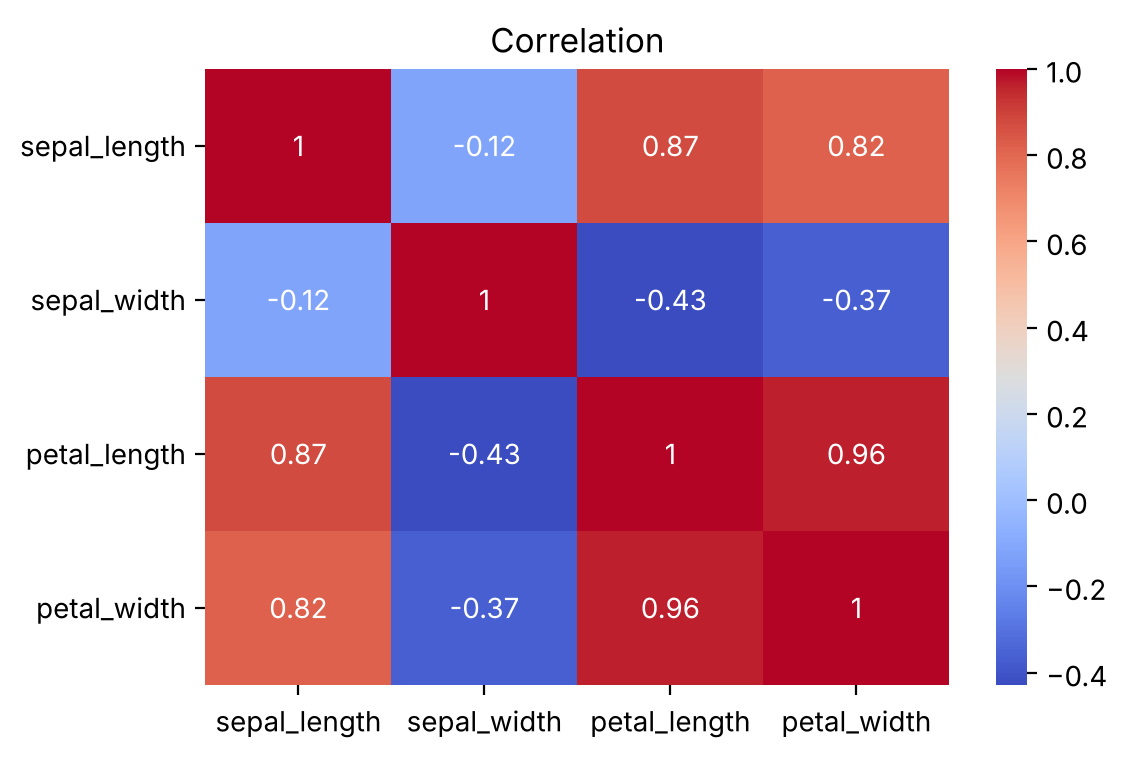

In [6]:
plt.figure(figsize=(6,4))
sns.heatmap(df.drop(columns='species').corr(), annot=True, cmap='coolwarm')
plt.title('Correlation')
plt.show()

Petal length and petal width are very strongly correlated (0.96).

## Train/test split and scaling

In [7]:
X = df.drop(columns='species')
y = df['species']

# 80/20 split, stratify so each species is split evenly
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


In [8]:
# fit the scaler on train only, then apply to test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Training the models

In [9]:
lr = LogisticRegression(max_iter=200)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train_scaled, y_train)
dt_pred = dt.predict(X_test_scaled)

## Results

In [10]:
def get_scores(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='macro'),
        'Recall': recall_score(y_true, y_pred, average='macro'),
        'F1': f1_score(y_true, y_pred, average='macro')
    }

results = pd.DataFrame({
    'Logistic Regression': get_scores(y_test, lr_pred),
    'Decision Tree': get_scores(y_test, dt_pred)
}).T

results.round(3)

,Accuracy,Precision,Recall,F1
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


In [11]:
print("Logistic Regression")
print(classification_report(y_test, lr_pred))

print("Decision Tree")
print(classification_report(y_test, dt_pred))

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Confusion matrices

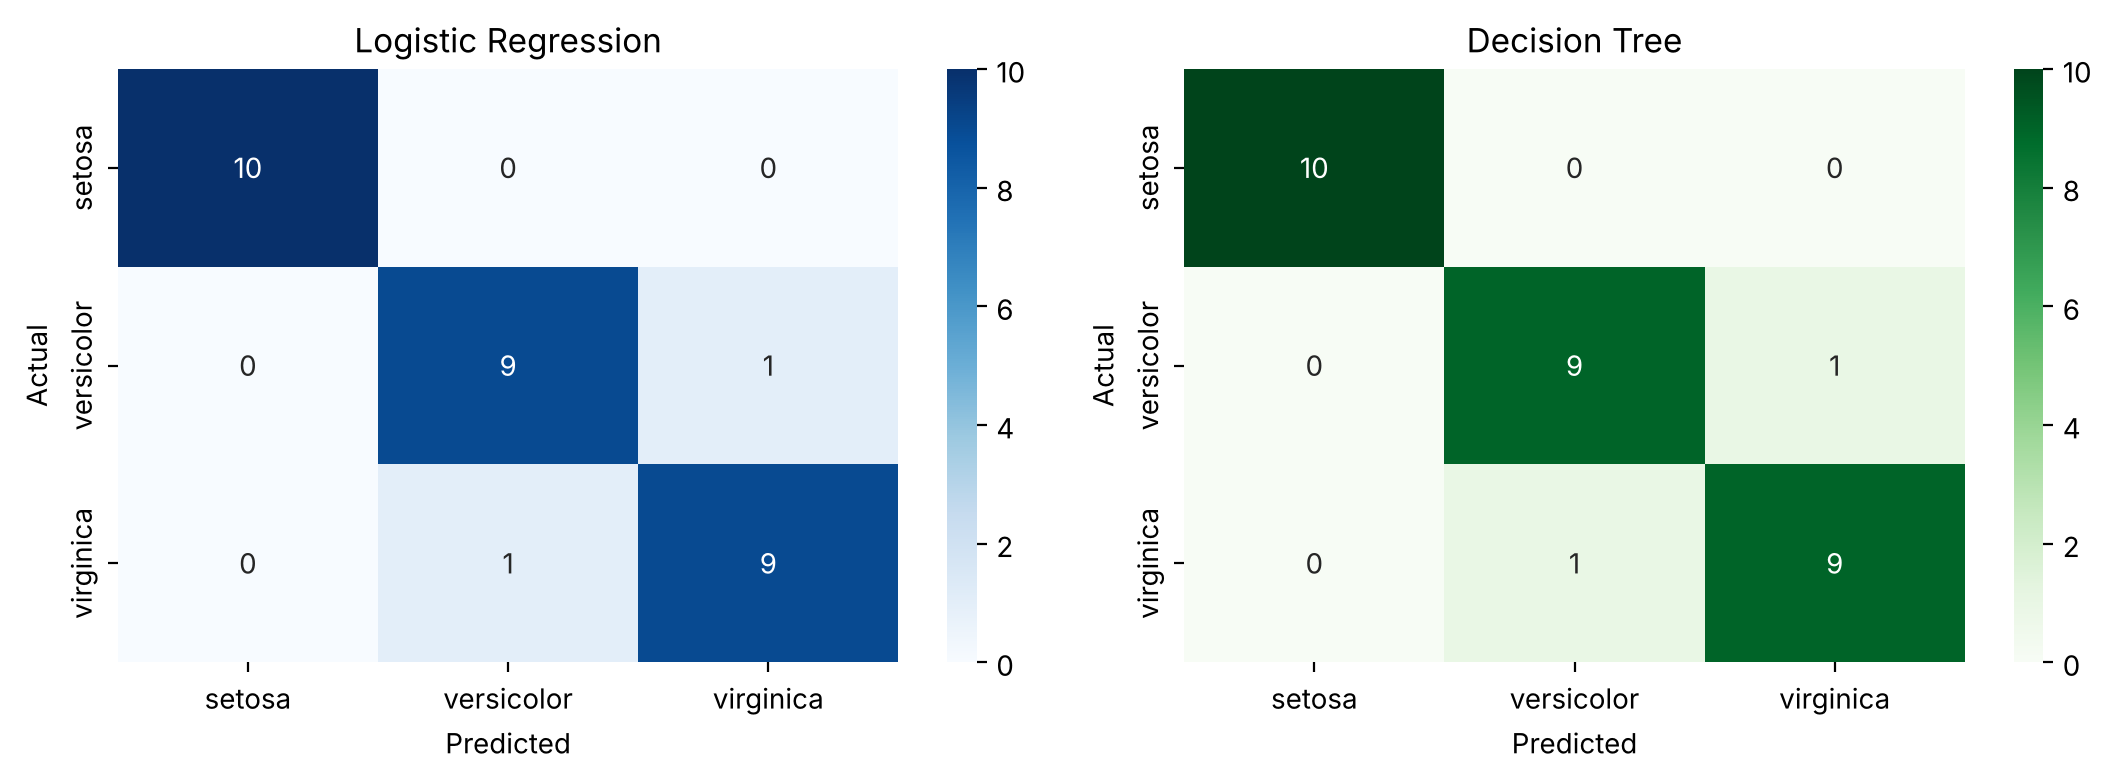

In [12]:
labels = sorted(y.unique())

fig, ax = plt.subplots(1, 2, figsize=(11,4))

sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=ax[0])
ax[0].set_title('Logistic Regression')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, cmap='Greens',
            xticklabels=labels, yticklabels=labels, ax=ax[1])
ax[1].set_title('Decision Tree')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Both models got setosa 100% right. Each one made 2 mistakes, 1 versicolor predicted as virginica and 1 virginica predicted as versicolor, which is what I expected from the pairplot.

## Decision boundary

You can only plot a decision boundary in 2D, so I retrained both models using just petal length and petal width since they were the most useful features in the EDA.

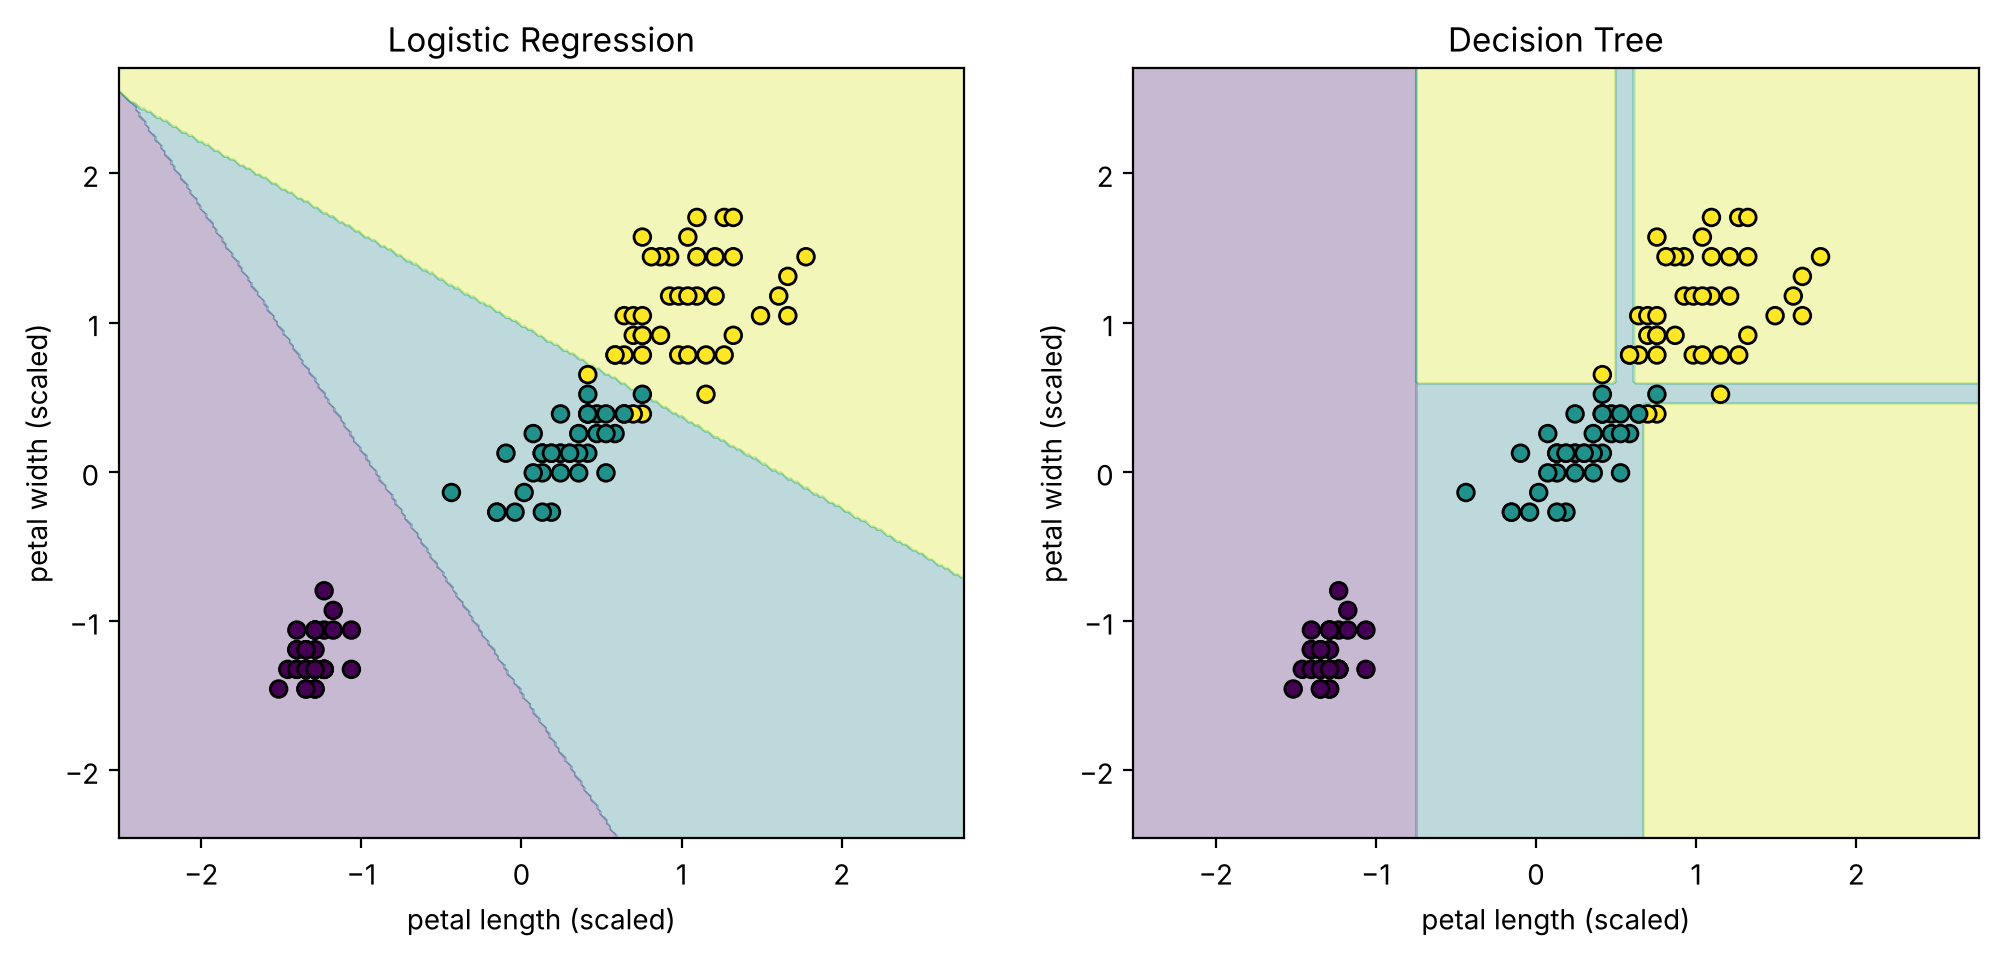

In [13]:
X2 = X_train[['petal_length', 'petal_width']]
sc2 = StandardScaler()
X2 = sc2.fit_transform(X2)

# convert species names to numbers so they can be plotted
codes = {'setosa': 0, 'versicolor': 1, 'virginica': 2}
y2 = y_train.map(codes)

xx, yy = np.meshgrid(np.arange(X2[:,0].min()-1, X2[:,0].max()+1, 0.02),
                     np.arange(X2[:,1].min()-1, X2[:,1].max()+1, 0.02))

fig, ax = plt.subplots(1, 2, figsize=(12,5))
for i, (name, model) in enumerate([('Logistic Regression', LogisticRegression(max_iter=200)),
                                   ('Decision Tree', DecisionTreeClassifier(max_depth=4, random_state=42))]):
    model.fit(X2, y2)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax[i].contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax[i].scatter(X2[:,0], X2[:,1], c=y2, cmap='viridis', edgecolor='k')
    ax[i].set_title(name)
    ax[i].set_xlabel('petal length (scaled)')
    ax[i].set_ylabel('petal width (scaled)')

plt.show()

Logistic regression splits the space with straight diagonal lines, while the decision tree makes box shaped regions because it splits on one feature at a time.

## Conclusion

Both models got the same scores on the test set (93.3% accuracy, 0.933 F1). They both only struggled with versicolor vs virginica.

Since the test set is only 30 rows, one wrong prediction changes accuracy by about 3%, so it's hard to say one model is better from this alone. Logistic regression gives smoother boundaries, but the decision tree is easier to explain because you can follow the splits.

Things I could try next: tuning the decision tree depth, using cross validation, or running the same pipeline on the Wine dataset.